# Деревья решений и ансамбли с нуля

Задача та же, что в проекте [lemon-cars-classification](https://github.com/idanrus/lemon-cars-classification): по данным о машине, купленной на аукционе, предсказать, окажется ли она «лимоном» (`IsBadBuy`). Данные: [Don't Get Kicked! (Kaggle)](https://www.kaggle.com/competitions/DontGetKicked/data).

Здесь с нуля написаны дерево решений (классификатор и регрессор), Extra Tree, случайный лес, Extra Trees и градиентный бустинг. Код моделей лежит в `trees.py`, каждая модель сверяется со `scikit-learn`. В конце те же данные решаются LightGBM, XGBoost и CatBoost.

Метрика: Gini = 2 * ROC AUC - 1.

## 1. Теория коротко

### Дерево решений (CART)
Дерево делит пространство признаков на прямоугольные области вопросами вида «признак $x_j \le t$?» и в каждой области (листе) отвечает константой. Найти лучшее дерево целиком слишком сложно, поэтому его строят жадно: в каждом узле перебираем все признаки и все пороги и берём сплит, после которого объекты в двух половинах самые «однородные». Качество сплита:

$$Q = H(R) - \frac{n_L}{n} H(R_L) - \frac{n_R}{n} H(R_R),$$

где $H$ это неопределённость в узле. Для классификации берём Gini impurity $H = 1 - p_0^2 - p_1^2$ ($p_k$ это доля класса $k$ в узле), для регрессии дисперсию таргета. Рост останавливаем на `max_depth` или когда в узле остался один класс. В листе классификатор отдаёт долю единиц (это и есть вероятность), регрессор среднее.

Чтобы перебор порогов был быстрым, признак сортируется один раз, а суммы таргета слева и справа считаются накопленными суммами. Порог ставим посередине между соседними разными значениями.

### Extra Tree
То же дерево, но порог по каждому признаку не ищется перебором, а выбирается случайно между минимумом и максимумом. Из таких случайных сплитов берём лучший. Одно такое дерево слабее обычного, зато деревья получаются сильно разными, и их удобно усреднять.

### Бэггинг и случайный лес
Одно глубокое дерево сильно переобучается и нестабильно: чуть поменяли данные, и дерево стало совсем другим. Если обучить много деревьев на разных бутстрэп-выборках (случайный выбор строк с повторениями) и усреднить их ответы, разброс заметно падает. Случайный лес добавляет ещё одну случайность: в каждом узле дерево смотрит только на часть признаков (обычно $\sqrt{d}$). Так деревья меньше похожи друг на друга, и от усреднения больше пользы. Extra Trees делает то же самое с Extra Tree вместо обычных деревьев и обычно без бутстрэпа.

### Градиентный бустинг
Деревья строятся по очереди, и каждое следующее исправляет ошибки суммы предыдущих. Модель считает логит

$$F(x) = F_0 + \eta \left(h_1(x) + h_2(x) + \dots\right), \quad p(x) = \sigma(F(x)).$$

Старт $F_0 = \log \frac{\bar y}{1 - \bar y}$: лучшая константа по логлоссу. Для логлосса $L = -y \log p - (1 - y) \log(1 - p)$ производная по логиту равна $\frac{\partial L}{\partial F} = p - y$. Значит, антиградиент это $y - p$: следующее дерево-регрессор учится предсказывать $y - p$, и мы делаем маленький шаг $\eta$ (learning rate) в эту сторону. Как и в лесе, каждое дерево можно учить на случайной части строк (`subsample`).

### LightGBM, XGBoost, CatBoost
Все три это градиентный бустинг над деревьями, отличаются деталями:
- **XGBoost** растит дерево по уровням (depthwise), в лист кладёт шаг Ньютона (использует не только градиент, но и вторую производную) и штрафует большие значения в листьях. Умеет режим **DART**: при построении нового дерева случайно «выключает» часть уже построенных деревьев, как dropout в нейросетях. Так поздние деревья не подстраиваются под мелкие ошибки ранних, и модель меньше переобучается, но учится медленнее.
- **LightGBM** растит дерево по листьям (leafwise): каждый раз делит тот лист, где выигрыш больше всего. Дерево получается несимметричным, это быстро и точно, но легче переобучиться, поэтому главный параметр сложности тут `num_leaves`. Пороги ищет по гистограммам признаков, поэтому очень быстрый. Умеет `linear_tree`: в листе вместо константы линейная регрессия.
- **CatBoost** строит симметричные (oblivious) деревья: на одном уровне все узлы делятся по одному и тому же условию. Это работает как сильная регуляризация, и предсказание очень быстрое. Главная фишка: сам работает с категориальными признаками. Категорию он заменяет на среднее таргета по этой категории, но считает его только по объектам, которые идут раньше в случайной перестановке (ordered target statistics). Так объект не видит свой собственный таргет, и утечки, как при обычном target encoding, нет.

## 2. Данные

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import roc_auc_score, mean_squared_error
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, ExtraTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier

from trees import (train_test_split, DecisionTreeClassifier_custom, DecisionTreeRegressor_custom,
                   ExtraTreeClassifier_custom, RandomForestClassifier_custom,
                   ExtraTreesClassifier_custom, GBDT_custom)

pd.set_option('display.max_columns', None)

In [2]:
df = pd.read_csv('data/training.csv', parse_dates=['PurchDate'])
target = df['IsBadBuy']
dates = df['PurchDate']

# id, колонки почти из одних пропусков, номер покупателя, индекс продавца, гарантия.
# Model убираем: в SubModel и Trim эта информация уже есть.
df = df.drop(columns=['IsBadBuy', 'PurchDate', 'RefId', 'WheelTypeID', 'AUCGUART', 'PRIMEUNIT',
                      'BYRNO', 'Model', 'WarrantyCost', 'VNZIP1'])

cat_cols = list(df.select_dtypes(exclude='number').columns)
num_cols = list(df.select_dtypes(include='number').columns)
print(df.shape, f'доля лимонов {target.mean():.3f}')
print('категориальные:', cat_cols)

(72983, 24) доля лимонов 0.123
категориальные: ['Auction', 'Make', 'Trim', 'SubModel', 'Color', 'Transmission', 'WheelType', 'Nationality', 'Size', 'TopThreeAmericanName', 'VNST']


Сначала делим по дате, потом заполняем пропуски и кодируем категории. Все статистики (средние для пропусков, список категорий для one-hot) считаем только по train, чтобы в модель не просочилась информация из будущего.

In [3]:
X_train_raw, X_valid_raw, X_test_raw, y_train, y_valid, y_test = train_test_split(
    df, target, test_size=1/3, valid_size=1/3, date_column=dates)

X_train_raw, X_valid_raw, X_test_raw = X_train_raw.copy(), X_valid_raw.copy(), X_test_raw.copy()
train_means = X_train_raw[num_cols].mean()
for X in [X_train_raw, X_valid_raw, X_test_raw]:
    for col in cat_cols:
        X[col] = X[col].fillna('unknown_' + col)
    X[num_cols] = X[num_cols].fillna(train_means)

print('train:', dates[X_train_raw.index].min().date(), '-', dates[X_train_raw.index].max().date(), len(X_train_raw))
print('valid:', dates[X_valid_raw.index].min().date(), '-', dates[X_valid_raw.index].max().date(), len(X_valid_raw))
print('test: ', dates[X_test_raw.index].min().date(), '-', dates[X_test_raw.index].max().date(), len(X_test_raw))

train: 2009-01-05 - 2009-09-15 24327
valid: 2009-09-15 - 2010-05-14 24328
test:  2010-05-14 - 2010-12-30 24328


In [4]:
# Редкие категории (реже 35 раз в train) и новые категории из valid/test уходят в общую колонку infrequent
preprocessor = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(drop='first', min_frequency=35, handle_unknown='infrequent_if_exist',
                                        sparse_output=False), cat_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

X_train = preprocessor.fit_transform(X_train_raw)
X_valid = preprocessor.transform(X_valid_raw)
X_test = preprocessor.transform(X_test_raw)
print(X_train.shape)

(24327, 265)


c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1, 2, 3, 5, 7, 8, 9, 10] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)
c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [1, 2, 3, 10] during transform. These unknown categories will be encoded as the infrequent category.
  warnings.warn(msg, UserWarning)


Пока выбираем модели, смотрим только на train и valid. Test трогаем один раз в самом конце.

In [5]:
def gini_score(model, X, y):
    return 2 * roc_auc_score(y, model.predict_proba(X)[:, 1]) - 1

results = {}  # имя модели -> (модель, на каких данных обучена)

def report(name, model, data='ohe'):
    Xtr, Xva = (X_train, X_valid) if data == 'ohe' else (X_train_raw, X_valid_raw)
    g_train, g_valid = gini_score(model, Xtr, y_train), gini_score(model, Xva, y_valid)
    results[name] = (model, data)
    print(f'{name}: train Gini {g_train:.4f}, valid Gini {g_valid:.4f}')

## 3. Своё дерево решений

### Регрессор (MSE)

In [6]:
for depth in [5, 10]:
    for model in [DecisionTreeRegressor(max_depth=depth), DecisionTreeRegressor_custom(max_depth=depth)]:
        model.fit(X_train, y_train)
        mse_train = mean_squared_error(y_train, model.predict(X_train))
        mse_valid = mean_squared_error(y_valid, model.predict(X_valid))
        print(f'{type(model).__name__}, depth {depth}: train MSE {mse_train:.4f}, valid MSE {mse_valid:.4f}')

DecisionTreeRegressor, depth 5: train MSE 0.0804, valid MSE 0.0950
DecisionTreeRegressor_custom, depth 5: train MSE 0.0804, valid MSE 0.0951
DecisionTreeRegressor, depth 10: train MSE 0.0701, valid MSE 0.1035
DecisionTreeRegressor_custom, depth 10: train MSE 0.0698, valid MSE 0.1060


### Классификатор (Gini)

In [7]:
start = time.time()
tree_sk = DecisionTreeClassifier(max_depth=5, random_state=21).fit(X_train, y_train)
print(f'sklearn: {time.time() - start:.2f} с')
start = time.time()
tree_custom = DecisionTreeClassifier_custom(max_depth=5).fit(X_train, y_train)
print(f'своё:    {time.time() - start:.2f} с')

report('DecisionTree (sklearn, depth 5)', tree_sk)
report('DecisionTree (своё, depth 5)', tree_custom)

sklearn: 0.21 с
своё:    1.43 с
DecisionTree (sklearn, depth 5): train Gini 0.4959, valid Gini 0.4498
DecisionTree (своё, depth 5): train Gini 0.4961, valid Gini 0.4488


Как меняется качество с глубиной: на train Gini растёт всегда, а на valid в какой-то момент начинает падать. Это и есть переобучение одиночного дерева.

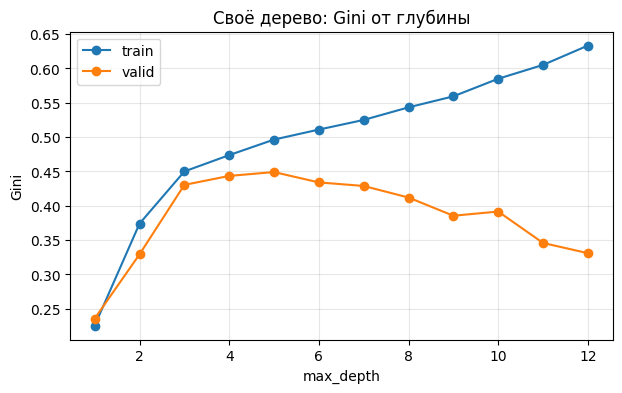

лучшая глубина на valid: 5


In [8]:
depths = range(1, 13)
g_train, g_valid = [], []
for depth in depths:
    model = DecisionTreeClassifier_custom(max_depth=depth).fit(X_train, y_train)
    g_train.append(gini_score(model, X_train, y_train))
    g_valid.append(gini_score(model, X_valid, y_valid))

plt.figure(figsize=(7, 4))
plt.plot(depths, g_train, marker='o', label='train')
plt.plot(depths, g_valid, marker='o', label='valid')
plt.xlabel('max_depth')
plt.ylabel('Gini')
plt.title('Своё дерево: Gini от глубины')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('images/depth_vs_gini.png', dpi=120, bbox_inches='tight')
plt.show()
best_depth = list(depths)[int(np.argmax(g_valid))]
print('лучшая глубина на valid:', best_depth)

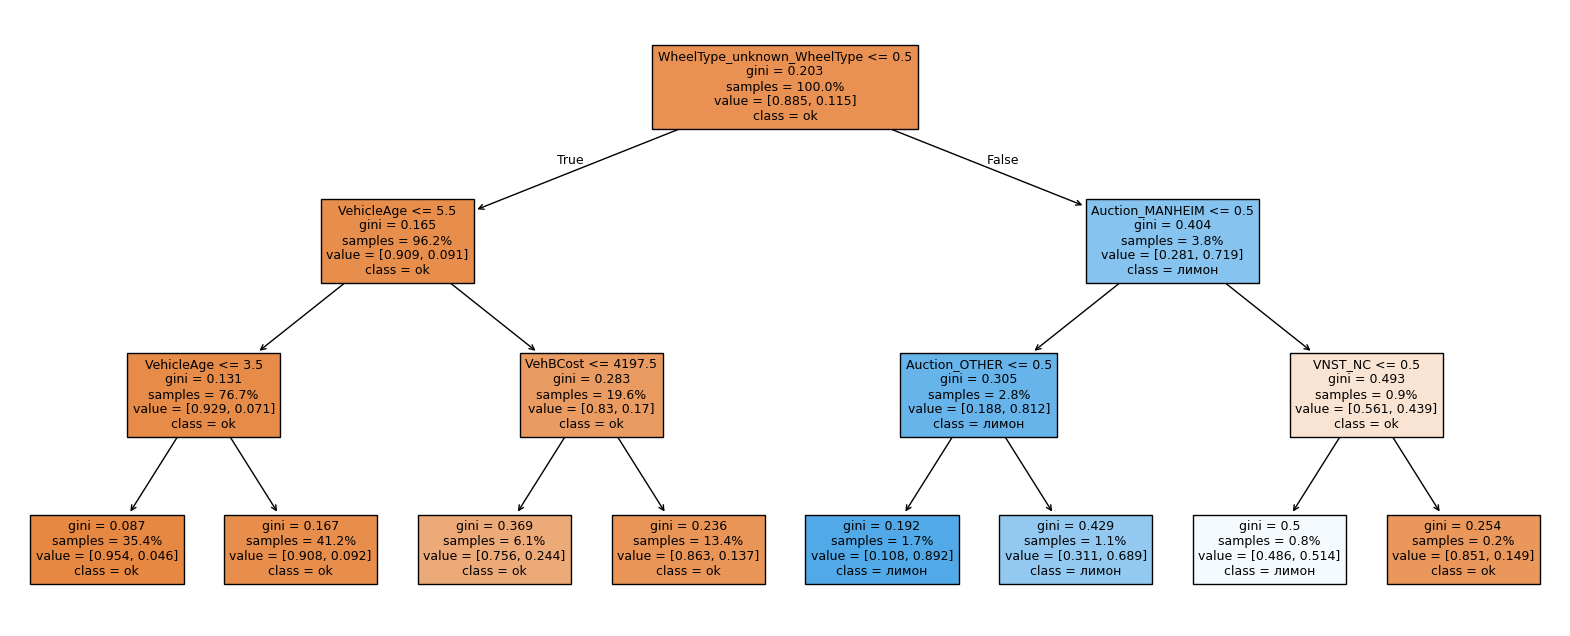

In [9]:
# Первые уровни дерева sklearn: по каким признакам дерево делит машины в первую очередь
plt.figure(figsize=(20, 8))
plot_tree(DecisionTreeClassifier(max_depth=3).fit(X_train, y_train), feature_names=list(X_train.columns),
          class_names=['ok', 'лимон'], filled=True, proportion=True, fontsize=9)
plt.savefig('images/tree.png', dpi=100, bbox_inches='tight')
plt.show()

**Вывод (шаги 3 и 4):** своё дерево глубины 5 даёт на valid Gini 0.449, порог задания 0.1 пройден с большим запасом. У sklearn 0.450, на train 0.4961 против 0.4959: деревья почти одинаковые, расходятся только там, где у двух сплитов одинаковое качество и мы выбираем разные. Регрессор на глубине 5 совпадает со sklearn по MSE. То есть по качеству sklearn не лучше, зато в 7 раз быстрее (0.21 с против 1.43 с): он написан на Cython и не создаёт копии данных в каждом узле.

Лучшая глубина на valid 5. Дальше Gini на train растёт до 0.63 на глубине 12, а на valid падает до 0.33: дерево начинает запоминать train.

## 4. Extra Tree

Для честного сравнения со sklearn ставим одинаковые параметры: смотрим все признаки и по одному случайному порогу на признак. Отдельно своё дерево с 10 случайными порогами: оно ближе к обычному дереву.

In [10]:
report('ExtraTree (sklearn, depth 5)', ExtraTreeClassifier(max_depth=5, max_features=None, random_state=21).fit(X_train, y_train))
report('ExtraTree (своё, depth 5)', ExtraTreeClassifier_custom(max_depth=5, n_random_splits=1, random_state=21).fit(X_train, y_train))
report('ExtraTree (своё, depth 5, 10 порогов)', ExtraTreeClassifier_custom(max_depth=5, n_random_splits=10, random_state=21).fit(X_train, y_train))

ExtraTree (sklearn, depth 5): train Gini 0.4754, valid Gini 0.4446
ExtraTree (своё, depth 5): train Gini 0.4738, valid Gini 0.4515
ExtraTree (своё, depth 5, 10 порогов): train Gini 0.4843, valid Gini 0.4381


## 5. Случайный лес

In [11]:
start = time.time()
rf_sk = RandomForestClassifier(n_estimators=100, max_depth=7, max_features='sqrt', random_state=21, n_jobs=-1).fit(X_train, y_train)
print(f'sklearn: {time.time() - start:.1f} с')
start = time.time()
rf_custom = RandomForestClassifier_custom(n_estimators=100, max_depth=7, max_features='sqrt', random_state=21).fit(X_train, y_train)
print(f'своё:    {time.time() - start:.1f} с')

report('RandomForest (sklearn)', rf_sk)
report('RandomForest (своё)', rf_custom)

sklearn: 0.5 с
своё:    29.4 с
RandomForest (sklearn): train Gini 0.5733, valid Gini 0.4670
RandomForest (своё): train Gini 0.5680, valid Gini 0.4659


In [12]:
# Фиксированный seed даёт одинаковый результат
rf_again = RandomForestClassifier_custom(n_estimators=10, max_depth=7, random_state=21).fit(X_train, y_train)
rf_again_2 = RandomForestClassifier_custom(n_estimators=10, max_depth=7, random_state=21).fit(X_train, y_train)
print(np.allclose(rf_again.predict_proba(X_valid), rf_again_2.predict_proba(X_valid)))

True


**Вывод (шаг 5):** свой лес даёт на valid 0.466 против 0.449 у одного дерева, порог 0.15 пройден. У sklearn 0.467, почти то же самое. Деревья в лесу глубже (7), поэтому разрыв train и valid у леса больше (0.57 против 0.47), но за счёт усреднения деревьев на разных строках и признаках valid всё равно выше, чем у одного дерева. Свой лес медленнее в 60 раз (29 с против 0.5 с): sklearn ещё и строит деревья параллельно.

## 6. Extra Trees (бонус)

In [13]:
report('ExtraTrees (sklearn)', ExtraTreesClassifier(n_estimators=100, max_depth=7, max_features='sqrt', random_state=21, n_jobs=-1).fit(X_train, y_train))
report('ExtraTrees (своё)', ExtraTreesClassifier_custom(n_estimators=100, max_depth=7, max_features='sqrt', random_state=21).fit(X_train, y_train))

ExtraTrees (sklearn): train Gini 0.5607, valid Gini 0.4691
ExtraTrees (своё): train Gini 0.5548, valid Gini 0.4699


**Вывод (шаг 9):** свой Extra Trees даёт на valid 0.470, это лучше одного Extra Tree (0.452) и порога 0.12. Со sklearn совпадает (0.469) и даже чуть лучше случайного леса (0.466). Одиночные Extra Tree со sklearn тоже близки (0.452 против 0.445), а 10 случайных порогов вместо одного одиночному дереву не помогли (0.438): разница между ними в пределах случайности.

## 7. Свой градиентный бустинг

In [14]:
start = time.time()
gb_sk = GradientBoostingClassifier(n_estimators=50, max_depth=3, learning_rate=0.2, subsample=0.8, random_state=21).fit(X_train, y_train)
print(f'sklearn: {time.time() - start:.1f} с')
start = time.time()
gbdt_custom = GBDT_custom(n_estimators=50, max_depth=3, max_features=None, learning_rate=0.2, subsample=0.8, random_state=21).fit(X_train, y_train)
print(f'своё:    {time.time() - start:.1f} с')

report('GradientBoosting (sklearn)', gb_sk)
report('GBDT (своё)', gbdt_custom)

sklearn: 4.6 с
своё:    48.4 с
GradientBoosting (sklearn): train Gini 0.5724, valid Gini 0.4867
GBDT (своё): train Gini 0.5027, valid Gini 0.4758


GBDT (своё, max_features=sqrt): train Gini 0.4929, valid Gini 0.4534


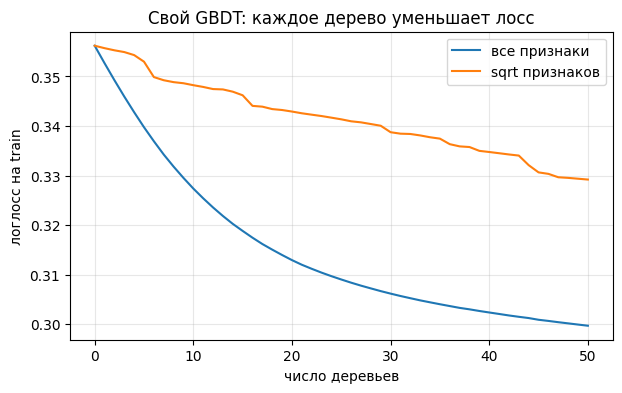

In [15]:
# max_features работает так же, как в лесе: в каждом узле смотрим только часть признаков
gbdt_sqrt = GBDT_custom(n_estimators=50, max_depth=3, max_features='sqrt', learning_rate=0.2, random_state=21).fit(X_train, y_train)
report('GBDT (своё, max_features=sqrt)', gbdt_sqrt)

plt.figure(figsize=(7, 4))
plt.plot(gbdt_custom.train_loss, label='все признаки')
plt.plot(gbdt_sqrt.train_loss, label='sqrt признаков')
plt.xlabel('число деревьев')
plt.ylabel('логлосс на train')
plt.title('Свой GBDT: каждое дерево уменьшает лосс')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Вывод (шаг 6):** свой GBDT даёт на valid 0.476, это лучше леса, но чуть хуже sklearn (0.487). Причём на train разница ещё больше (0.503 против 0.572): мой бустинг просто недообучен за 50 деревьев. Причина в значении листа: у меня в листе среднее антиградиента $y - p$, а sklearn делает шаг Ньютона $\frac{\sum (y - p)}{\sum p(1 - p)}$. Так как $p(1 - p) \le 0.25$, шаг у sklearn в несколько раз больше, и при том же learning rate он учится быстрее. С `max_features='sqrt'` стало хуже (0.453): каждое дерево видит 16 признаков из 265 и часто не видит самый важный `WheelType`, это видно по ступенькам на графике лосса.

## 8. LightGBM, XGBoost, CatBoost

У всех трёх ставим много деревьев и маленький learning rate, а число деревьев выбирает ранняя остановка по valid. Дальше небольшой перебор пары параметров, которые сильнее всего влияют на сложность деревьев. Так как и остановка, и выбор параметров смотрят на valid, оценка на valid немного оптимистична, честную оценку даст test в конце.

### LightGBM

In [16]:
best_gini, best_lgb = -1, None
for num_leaves in [7, 15, 31, 63]:
    for min_child_samples in [20, 100, 300]:
        model = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.03, num_leaves=num_leaves,
                                   min_child_samples=min_child_samples, subsample=0.8, subsample_freq=1,
                                   colsample_bytree=0.8, random_state=21, verbose=-1)
        model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], eval_metric='auc',
                  callbacks=[lgb.early_stopping(100, verbose=False)])
        g = gini_score(model, X_valid, y_valid)
        print(f'num_leaves={num_leaves}, min_child_samples={min_child_samples}: '
              f'деревьев {model.best_iteration_}, valid Gini {g:.4f}')
        if g > best_gini:
            best_gini, best_lgb = g, model
report('LightGBM', best_lgb)

c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\User\AppData\Local\Programs\Python\Python313\Lib\subprocess.py", line 1036, in __init__


num_leaves=7, min_child_samples=20: деревьев 284, valid Gini 0.4867
num_leaves=7, min_child_samples=100: деревьев 325, valid Gini 0.4891
num_leaves=7, min_child_samples=300: деревьев 464, valid Gini 0.4876
num_leaves=15, min_child_samples=20: деревьев 166, valid Gini 0.4895
num_leaves=15, min_child_samples=100: деревьев 194, valid Gini 0.4890
num_leaves=15, min_child_samples=300: деревьев 208, valid Gini 0.4827
num_leaves=31, min_child_samples=20: деревьев 157, valid Gini 0.4866
num_leaves=31, min_child_samples=100: деревьев 114, valid Gini 0.4837
num_leaves=31, min_child_samples=300: деревьев 123, valid Gini 0.4780
num_leaves=63, min_child_samples=20: деревьев 93, valid Gini 0.4847
num_leaves=63, min_child_samples=100: деревьев 91, valid Gini 0.4767
num_leaves=63, min_child_samples=300: деревьев 95, valid Gini 0.4746
LightGBM: train Gini 0.6250, valid Gini 0.4895


In [17]:
# linear_tree: в листе линейная модель вместо константы
lgb_linear = lgb.LGBMClassifier(n_estimators=100, max_depth=5, learning_rate=0.1, subsample=0.8, subsample_freq=1,
                                colsample_bytree=0.8, linear_tree=True, random_state=21, verbose=-1).fit(X_train, y_train)
report('LightGBM linear_tree', lgb_linear)

LightGBM linear_tree: train Gini 0.7152, valid Gini 0.4803


### XGBoost

In [18]:
best_gini, best_xgb = -1, None
for max_depth in [3, 4, 6]:
    for min_child_weight in [1, 10, 30]:
        model = xgb.XGBClassifier(n_estimators=2000, learning_rate=0.03, max_depth=max_depth,
                                  min_child_weight=min_child_weight, subsample=0.8, colsample_bytree=0.8,
                                  eval_metric='auc', early_stopping_rounds=100, random_state=21)
        model.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
        g = gini_score(model, X_valid, y_valid)
        print(f'max_depth={max_depth}, min_child_weight={min_child_weight}: '
              f'деревьев {model.best_iteration + 1}, valid Gini {g:.4f}')
        if g > best_gini:
            best_gini, best_xgb = g, model
report('XGBoost', best_xgb)

max_depth=3, min_child_weight=1: деревьев 587, valid Gini 0.4968
max_depth=3, min_child_weight=10: деревьев 490, valid Gini 0.4935
max_depth=3, min_child_weight=30: деревьев 526, valid Gini 0.4895
max_depth=4, min_child_weight=1: деревьев 509, valid Gini 0.4956
max_depth=4, min_child_weight=10: деревьев 483, valid Gini 0.4959
max_depth=4, min_child_weight=30: деревьев 398, valid Gini 0.4887
max_depth=6, min_child_weight=1: деревьев 158, valid Gini 0.4904
max_depth=6, min_child_weight=10: деревьев 189, valid Gini 0.4908
max_depth=6, min_child_weight=30: деревьев 169, valid Gini 0.4875
XGBoost: train Gini 0.6131, valid Gini 0.4968


In [19]:
# DART с лучшими параметрами. Ранняя остановка с DART работает плохо (выключенные деревья
# меняются на каждой итерации), поэтому берём фиксированное число деревьев.
params = best_xgb.get_params()
xgb_dart = xgb.XGBClassifier(booster='dart', rate_drop=0.1, skip_drop=0.5,
                             n_estimators=300, learning_rate=0.1, max_depth=params['max_depth'],
                             min_child_weight=params['min_child_weight'], subsample=0.8, colsample_bytree=0.8,
                             random_state=21)
xgb_dart.fit(X_train, y_train)
report('XGBoost DART', xgb_dart)

XGBoost DART: train Gini 0.6025, valid Gini 0.4892


### CatBoost

CatBoost получает исходные категории, без one-hot. Для сравнения тот же CatBoost на one-hot данных.

In [20]:
best_gini, best_cat = -1, None
for depth in [4, 6, 8]:
    for l2_leaf_reg in [3, 10]:
        model = CatBoostClassifier(iterations=3000, learning_rate=0.03, depth=depth, l2_leaf_reg=l2_leaf_reg,
                                   eval_metric='AUC', early_stopping_rounds=200, random_seed=21, verbose=0)
        model.fit(X_train_raw, y_train, cat_features=cat_cols, eval_set=(X_valid_raw, y_valid))
        g = gini_score(model, X_valid_raw, y_valid)
        print(f'depth={depth}, l2_leaf_reg={l2_leaf_reg}: деревьев {model.get_best_iteration() + 1}, valid Gini {g:.4f}')
        if g > best_gini:
            best_gini, best_cat = g, model
report('CatBoost (категории)', best_cat, data='raw')

depth=4, l2_leaf_reg=3: деревьев 789, valid Gini 0.4892
depth=4, l2_leaf_reg=10: деревьев 655, valid Gini 0.4898
depth=6, l2_leaf_reg=3: деревьев 260, valid Gini 0.4837
depth=6, l2_leaf_reg=10: деревьев 543, valid Gini 0.4900
depth=8, l2_leaf_reg=3: деревьев 436, valid Gini 0.4871
depth=8, l2_leaf_reg=10: деревьев 696, valid Gini 0.4934
CatBoost (категории): train Gini 0.6308, valid Gini 0.4934


In [21]:
cat_ohe = CatBoostClassifier(iterations=3000, learning_rate=0.03, depth=best_cat.get_params()['depth'],
                             l2_leaf_reg=best_cat.get_params()['l2_leaf_reg'], eval_metric='AUC',
                             early_stopping_rounds=200, random_seed=21, verbose=0)
cat_ohe.fit(X_train, y_train, eval_set=(X_valid, y_valid))
report('CatBoost (one-hot)', cat_ohe)

CatBoost (one-hot): train Gini 0.6159, valid Gini 0.4908


**Вывод (шаг 7):** лучший на valid XGBoost: 0.497 (глубина 3, 587 деревьев). Дальше CatBoost на категориях 0.493, CatBoost на one-hot 0.491 и LightGBM 0.490. Все четыре в пределах 0.01, то есть на этих данных библиотеки дают почти одно и то же, а главное это маленький learning rate и ранняя остановка. Почему XGBoost чуть впереди, по такой разнице честно сказать нельзя: на test порядок уже другой (лучший LightGBM 0.508).

Во всех библиотеках выиграли неглубокие деревья (у LightGBM 15 листьев, у XGBoost глубина 3-4): основной сигнал простой и держится на нескольких признаках. Исходные категории CatBoost дали на valid +0.003 по сравнению с one-hot, а на test наоборот, так что разницы нет. LightGBM с `linear_tree` сильно переобучен: train 0.715 при valid 0.480. DART с 300 деревьями без ранней остановки дал 0.489, хуже обычного XGBoost и заметно медленнее.

## 9. Итог: лучшая модель на test

In [22]:
table = pd.DataFrame([
    {'модель': name,
     'train Gini': gini_score(model, X_train if data == 'ohe' else X_train_raw, y_train),
     'valid Gini': gini_score(model, X_valid if data == 'ohe' else X_valid_raw, y_valid)}
    for name, (model, data) in results.items()
]).sort_values('valid Gini', ascending=False).reset_index(drop=True)
table.round(4)

,модель,train Gini,valid Gini
0,XGBoost,0.6131,0.4968
1,CatBoost (категории),0.6308,0.4934
2,CatBoost (one-hot),0.6159,0.4908
3,LightGBM,0.6250,0.4895
4,XGBoost DART,0.6025,0.4892
5,GradientBoosting (sklearn),0.5724,0.4867
6,LightGBM linear_tree,0.7152,0.4803
7,GBDT (своё),0.5027,0.4758
8,ExtraTrees (своё),0.5548,0.4699
9,ExtraTrees (sklearn),0.5607,0.4691


Лучшую модель выбираем только по valid. Теперь первый раз смотрим на test.

In [23]:
best_name = table.loc[0, 'модель']
best_model, best_data = results[best_name]
X_te = X_test if best_data == 'ohe' else X_test_raw
print(best_name)
print(f"train Gini {table.loc[0, 'train Gini']:.4f}")
print(f"valid Gini {table.loc[0, 'valid Gini']:.4f}")
print(f'test Gini  {gini_score(best_model, X_te, y_test):.4f}')

XGBoost
train Gini 0.6131
valid Gini 0.4968
test Gini  0.5064


In [24]:
# Для README: test Gini всех моделей (выбор уже сделан, на него это не влияет)
table['test Gini'] = [gini_score(results[name][0], X_test if results[name][1] == 'ohe' else X_test_raw, y_test)
                      for name in table['модель']]
table.round(4)

,модель,train Gini,valid Gini,test Gini
0,XGBoost,0.6131,0.4968,0.5064
1,CatBoost (категории),0.6308,0.4934,0.5027
2,CatBoost (one-hot),0.6159,0.4908,0.5073
3,LightGBM,0.6250,0.4895,0.5081
4,XGBoost DART,0.6025,0.4892,0.5066
5,GradientBoosting (sklearn),0.5724,0.4867,0.4988
6,LightGBM linear_tree,0.7152,0.4803,0.4901
7,GBDT (своё),0.5027,0.4758,0.4861
8,ExtraTrees (своё),0.5548,0.4699,0.4935
9,ExtraTrees (sklearn),0.5607,0.4691,0.4907


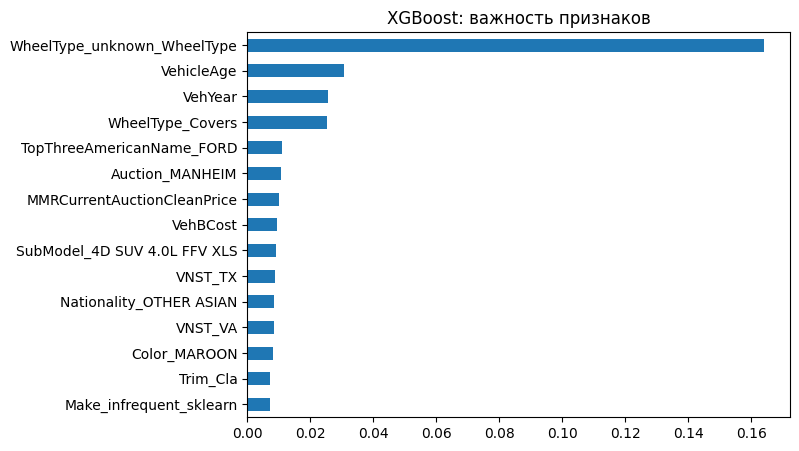

In [25]:
importance = pd.Series(best_model.feature_importances_, index=best_model.feature_names_
                       if hasattr(best_model, 'feature_names_') else X_te.columns)
importance.sort_values().tail(15).plot.barh(figsize=(7, 5), title=f'{best_name}: важность признаков')
plt.savefig('images/feature_importance.png', dpi=120, bbox_inches='tight')
plt.show()

**Вывод (шаг 8):** у XGBoost train Gini 0.613, valid 0.497, test 0.506. Просадки на test нет, test даже немного выше valid, и так почти у всех моделей: видимо, последний период просто чуть легче. Разрыв train и valid около 0.12, то есть модель подстроилась под train сильнее, чем это переносится на новые данные. Но ранняя остановка остановила её вовремя: следующие деревья поднимали бы train, а valid уже нет. Так что сильного переобучения нет, как у `linear_tree`.

## 10. Выводы

- Лучшая модель XGBoost: test Gini 0.506. Логистическая регрессия из прошлого проекта давала 0.487, бустинг лучше на 0.02. Прирост небольшой, потому что почти весь сигнал в нескольких признаках, и линейная модель их тоже хорошо ловит.
- Ансамбли заметно лучше одного дерева: на test одно дерево 0.456, свой лес 0.487, бустинги около 0.50-0.51.
- Свои реализации совпадают со sklearn: дерево почти один в один, лес и Extra Trees в пределах 0.002 на valid. Свой GBDT слабее на 0.01 из-за более простого значения в листе. Медленнее sklearn в 7-60 раз.
- Самый важный признак с большим отрывом: пропуск в типе колёс (`WheelType` unknown). Дальше возраст машины и год выпуска. То же самое было в проекте с логистической регрессией.